In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
from scipy.cluster.hierarchy import cut_tree, dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from rfm_sp500 import constants

In [2]:
df = pd.read_csv(constants.PROCESSED_DATA_DIR / "features.csv.gz", index_col=0)
print(df.shape)

(494, 8)


Feature preparation

In [3]:
rfm_columns = ["Recency", "Frequency", "Monetary"]
risk_columns = ["Mean_Weekly_Return", "Beta"]

X_risk = df[risk_columns].copy()

X_rfm = df[rfm_columns].copy()
X_rfm["Monetary"] = np.log1p(X_rfm["Monetary"])
X_rfm["Recency"] = np.log1p(X_rfm["Recency"])

In [4]:
print("Skew after transformation:")
print(pd.concat([X_risk, X_rfm], axis=1).skew().round(2))

Skew after transformation:
Mean_Weekly_Return    0.98
Beta                  1.26
Recency               1.54
Frequency             0.42
Monetary              1.07
dtype: float64


In [5]:
X_risk_scaled = StandardScaler().fit_transform(X_risk)
X_rfm_scaled = StandardScaler().fit_transform(X_rfm)


# Making sure there is a mean of 0 and variance of 1 after scaling

print(
    "\nRisk - means:",
    X_risk_scaled.mean(axis=0).round(2),
    ", std:",
    X_risk_scaled.std(axis=0).round(2),
)
print(
    "RFM - means:", X_rfm_scaled.mean(axis=0).round(2), ", std:", X_rfm_scaled.std(axis=0).round(2)
)


Risk - means: [ 0. -0.] , std: [1. 1.]
RFM - means: [-0. -0.  0.] , std: [1. 1. 1.]


Ward Dendograms

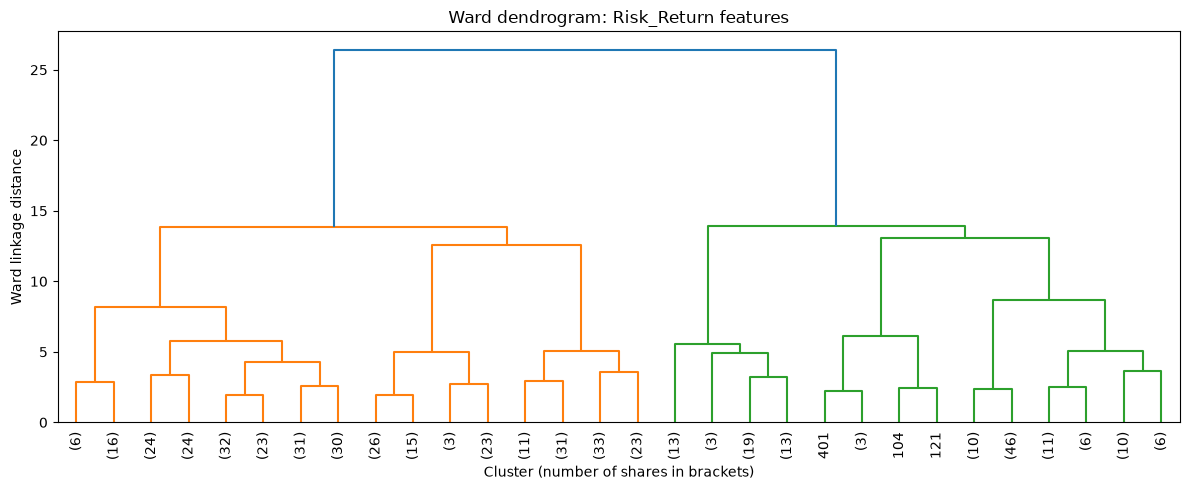

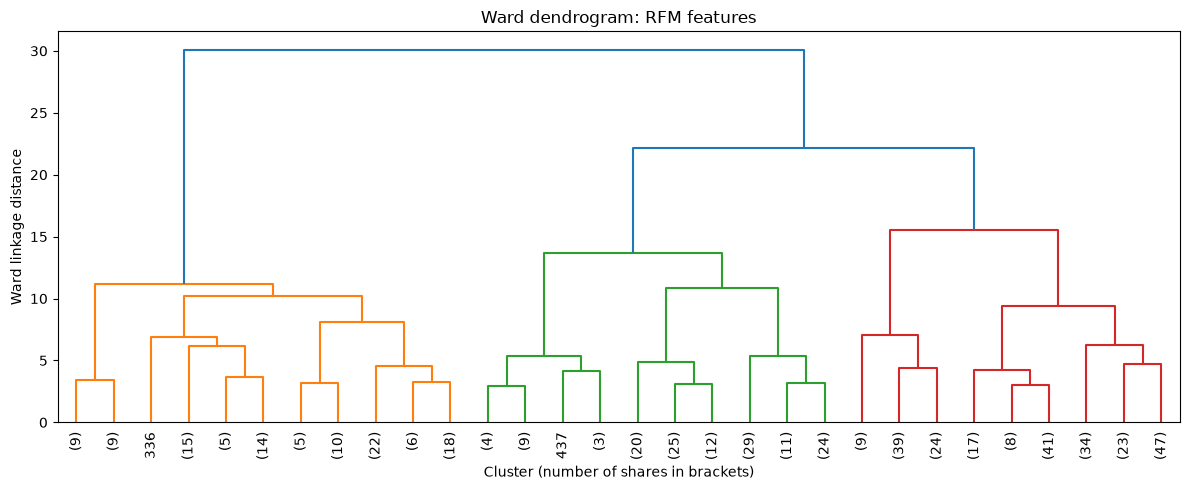

In [6]:
for name, X_scaled in [("Risk_Return", X_risk_scaled), ("RFM", X_rfm_scaled)]:
    hierarchy = linkage(X_scaled, method="ward")
    plt.figure(figsize=(12, 5))
    dendrogram(hierarchy, truncate_mode="lastp", p=30, leaf_rotation=90)
    plt.title(f"Ward dendrogram: {name} features")
    plt.xlabel("Cluster (number of shares in brackets)")
    plt.ylabel("Ward linkage distance")
    plt.tight_layout()
    plt.savefig(constants.FIGURES_DIR / f"dendrogram_{name}.png", dpi=150)
    plt.show()

Comparing k 2 to 8 

In [7]:
def create_table(X_scaled):
    hierarchy = linkage(X_scaled, method="ward")
    rows = []
    for k in range(2, 9):
        labels = cut_tree(hierarchy, n_clusters=k).ravel()
        sizes = np.bincount(labels)
        rows.append(
            {
                "k": k,
                "Silhouette": round(silhouette_score(X_scaled, labels), 3),
                "Smallest_cluster": sizes.min(),
                "Sizes": sorted(sizes, reverse=True),
            }
        )
    return pd.DataFrame(rows).set_index("k")

In [8]:
create_table(X_risk_scaled)

,Silhouette,Smallest_cluster,Sizes
k,,,
2,0.388,143,"[351, 143]"
3,0.359,48,"[351, 95, 48]"
4,0.273,48,"[186, 165, 95, 48]"
5,0.291,6,"[186, 165, 89, 48, 6]"
6,0.318,6,"[186, 98, 89, 67, 48, 6]"
7,0.308,6,"[186, 98, 67, 56, 48, 33, 6]"
8,0.321,6,"[164, 98, 67, 56, 48, 33, 22, 6]"


In [9]:
create_table(X_rfm_scaled)

,Silhouette,Smallest_cluster,Sizes
k,,,
2,0.398,114,"[380, 114]"
3,0.328,114,"[242, 138, 114]"
4,0.287,72,"[170, 138, 114, 72]"
5,0.306,17,"[170, 121, 114, 72, 17]"
6,0.290,17,"[170, 121, 96, 72, 18, 17]"
7,0.288,17,"[170, 96, 72, 64, 57, 18, 17]"
8,0.300,17,"[170, 72, 64, 61, 57, 35, 18, 17]"


In [10]:
def create_table2(X_scaled):
    rows = []
    for k in range(2, 9):
        kmeans = KMeans(n_clusters=k, n_init=20, random_state=constants.SEED)
        kmeans.fit(X_scaled)
        sizes = np.bincount(kmeans.labels_)
        rows.append(
            {
                "k": k,
                "Silhouette": round(silhouette_score(X_scaled, kmeans.labels_), 3),
                "Inertia": round(kmeans.inertia_, 1),
                "Smallest_cluster": sizes.min(),
                "Sizes": sorted(sizes, reverse=True),
            }
        )
    return pd.DataFrame(rows).set_index("k")


kmeans_risk = create_table2(X_risk_scaled)
kmeans_rfm = create_table2(X_rfm_scaled)

In [11]:
kmeans_risk

,Silhouette,Inertia,Smallest_cluster,Sizes
k,,,,
2,0.393,625.7,146,"[348, 146]"
3,0.317,476.5,121,"[208, 165, 121]"
4,0.325,374.9,41,"[169, 153, 131, 41]"
5,0.339,314.3,18,"[156, 135, 132, 53, 18]"
6,0.339,260.9,7,"[161, 128, 106, 52, 40, 7]"
7,0.335,224.9,7,"[144, 92, 87, 75, 48, 41, 7]"
8,0.358,193.2,7,"[138, 77, 77, 76, 49, 40, 30, 7]"


In [12]:
kmeans_rfm

,Silhouette,Inertia,Smallest_cluster,Sizes
k,,,,
2,0.415,1013.7,105,"[389, 105]"
3,0.342,756.9,95,"[259, 140, 95]"
4,0.361,569.2,85,"[196, 121, 92, 85]"
5,0.349,487.5,42,"[143, 120, 99, 90, 42]"
6,0.343,428.5,31,"[142, 117, 96, 71, 37, 31]"
7,0.339,385.4,22,"[136, 101, 70, 69, 64, 32, 22]"
8,0.334,349.1,24,"[134, 69, 68, 66, 58, 44, 31, 24]"


Elbow and silhouette plots

In [13]:
for name, table in [("Risk_Return", kmeans_risk), ("RFM", kmeans_rfm)]:
    fig = px.line(
        table.reset_index(),
        x="k",
        y="Inertia",
        markers=True,
        title=f"The Elbow Method: {name} features",
    )
    fig.write_image(constants.FIGURES_DIR / f"elbow_{name}.png")
    fig.show()

    fig = px.line(
        table.reset_index(),
        x="k",
        y="Silhouette",
        markers=True,
        title=f"K-means silhouette: {name} features",
    )
    fig.write_image(constants.FIGURES_DIR / f"silhouette_{name}.png")
    fig.show()

Solutions

In [14]:
k_risk, k_rfm = 3, 4

clusters = pd.DataFrame(index=df.index)
clusters["Ward_Risk"] = (
    cut_tree(linkage(X_risk_scaled, method="ward"), n_clusters=k_risk).ravel() + 1
)
clusters["KMeans_Risk"] = (
    KMeans(n_clusters=k_risk, n_init=20, random_state=constants.SEED).fit_predict(X_risk_scaled) + 1
)
clusters["Ward_RFM"] = cut_tree(linkage(X_rfm_scaled, method="ward"), n_clusters=k_rfm).ravel() + 1
clusters["KMeans_RFM"] = (
    KMeans(n_clusters=k_rfm, n_init=20, random_state=constants.SEED).fit_predict(X_rfm_scaled) + 1
)

full = df.join(clusters)
full.to_csv(constants.PROCESSED_DATA_DIR / "features_with_clusters.csv.gz")
full.head()

,Beta,Paired_weeks,Mean_Weekly_Return,Recency,Frequency,Monetary,Security,GICS Sector,Ward_Risk,KMeans_Risk,Ward_RFM,KMeans_RFM
Share,,,,,,,,,,,,
A,1.074724,207,0.001121,11,2,1.400180e+10,Agilent Technologies,Health Care,1,2,1,1
AAPL,1.174836,207,0.003930,11,2,6.233034e+11,Apple Inc.,Information Technology,2,3,2,2
ABBV,0.425366,207,0.003749,11,3,6.837054e+10,AbbVie,Health Care,1,1,2,2
ABNB,1.472709,207,0.001475,11,3,3.652850e+10,Airbnb,Consumer Discretionary,3,2,2,2
ABT,0.583543,207,0.000971,11,1,3.523027e+10,Abbott Laboratories,Health Care,1,1,2,1


In [15]:
for solution in ["Ward_Risk", "KMeans_Risk"]:
    profile = full.groupby(solution)[risk_columns].mean()
    profile["Count"] = full[solution].value_counts()
    print(solution)
    display(profile.round(4))

for solution in ["Ward_RFM", "KMeans_RFM"]:
    profile = full.groupby(solution)[rfm_columns].mean()
    profile["Median_Monetary"] = full.groupby(solution)["Monetary"].median()
    profile["Count"] = full[solution].value_counts()
    print(solution)
    display(profile.round(4))

Ward_Risk


,Mean_Weekly_Return,Beta,Count
Ward_Risk,,,
1,0.0021,0.7968,351
2,0.0065,1.3259,95
3,0.0022,1.6282,48


KMeans_Risk


,Mean_Weekly_Return,Beta,Count
KMeans_Risk,,,
1,0.0026,0.6375,208
2,0.0010,1.1349,165
3,0.0061,1.3550,121


Ward_RFM


,Recency,Frequency,Monetary,Median_Monetary,Count
Ward_RFM,,,,,
1,11.1706,2.7059,1.043702e+10,9.320572e+09,170
2,11.7971,2.9348,8.410759e+10,4.066914e+10,138
3,11.0556,4.6806,1.463893e+10,1.376417e+10,72
4,51.4123,2.4298,4.541574e+10,2.095020e+10,114


KMeans_RFM


,Recency,Frequency,Monetary,Median_Monetary,Count
KMeans_RFM,,,,,
1,11.3316,2.3622,1.501854e+10,1.320779e+10,196
2,13.5765,3.2824,1.245442e+11,6.466641e+10,85
3,13.2645,4.5455,1.474935e+10,1.269634e+10,121
4,56.5652,2.0326,4.671717e+10,2.145008e+10,92


In [16]:
for solution in ["Ward_Risk", "KMeans_Risk"]:
    order = [str(c) for c in sorted(full[solution].unique())]
    fig = px.scatter(
        full,
        x="Beta",
        y="Mean_Weekly_Return",
        color=full[solution].astype(str),
        hover_name=full.index,
        labels={"color": "Cluster"},
        title=f"{solution} clusters: beta vs mean weekly return",
        category_orders={"color": order},
    )
    fig.update_yaxes(tickformat=".1%", title="Mean weekly return")
    fig.update_xaxes(title="Beta")
    fig.write_image(constants.FIGURES_DIR / f"scatter_{solution}.png")
    fig.show()


for solution in ["Ward_RFM", "KMeans_RFM"]:
    order = [str(c) for c in sorted(full[solution].unique())]

    fig = px.scatter(
        full,
        x="Frequency",
        y="Monetary",
        log_y=True,
        color=full[solution].astype(str),
        hover_name=full.index,
        labels={"color": "Cluster"},
        title=f"{solution} clusters: Frequency vs Monetary (log scale)",
        category_orders={"color": order},
    )
    fig.update_yaxes(tickprefix="$", title="Monetary (USD, log scale)")
    fig.update_xaxes(title="Frequency (high-volume days)")
    fig.write_image(constants.FIGURES_DIR / f"scatter_{solution}.png")
    fig.show()

    fig = px.scatter(
        full,
        x="Recency",
        y="Frequency",
        log_x=True,
        color=full[solution].astype(str),
        hover_name=full.index,
        labels={"color": "Cluster"},
        title=f"{solution} clusters: Recency (log scale) vs Frequency",
        category_orders={"color": order},
    )
    fig.update_xaxes(title="Recency (days, log scale)")
    fig.update_yaxes(title="Frequency (high-volume days)")
    fig.write_image(constants.FIGURES_DIR / f"scatter_RF_{solution}.png")
    fig.show()

Comparison

In [17]:
for ward_col, kmeans_col in [("Ward_Risk", "KMeans_Risk"), ("Ward_RFM", "KMeans_RFM")]:
    print(
        f"{ward_col} vs {kmeans_col}:"
        f" adjusted Rand index = {adjusted_rand_score(full[ward_col], full[kmeans_col]):.3f}"
    )
    display(pd.crosstab(full[ward_col], full[kmeans_col]))

Ward_Risk vs KMeans_Risk: adjusted Rand index = 0.370


KMeans_Risk,1,2,3
Ward_Risk,,,
1,208,131,12
2,0,3,92
3,0,31,17


Ward_RFM vs KMeans_RFM: adjusted Rand index = 0.525


KMeans_RFM,1,2,3,4
Ward_RFM,,,,
1,147,0,23,0
2,46,78,14,0
3,0,0,72,0
4,3,7,12,92


In [18]:
rfm_check = pd.DataFrame(
    {
        "Recency": df["Recency"],
        "Frequency": df["Frequency"],
        "log1p_Monetary": np.log1p(df["Monetary"]),
    }
)
print("Correlations (Pearson):")
display(rfm_check.corr().round(3))
print("Correlations of the actual clustering inputs (log1p Recency, Frequency, log1p Monetary):")
display(X_rfm.corr().round(3))

Correlations (Pearson):


,Recency,Frequency,log1p_Monetary
Recency,1.000,-0.345,0.163
Frequency,-0.345,1.000,0.020
log1p_Monetary,0.163,0.020,1.000


Correlations of the actual clustering inputs (log1p Recency, Frequency, log1p Monetary):


,Recency,Frequency,Monetary
Recency,1.000,-0.284,0.143
Frequency,-0.284,1.000,0.020
Monetary,0.143,0.020,1.000


In [19]:
X_rf = df[["Recency", "Frequency"]].copy()
X_rf["Recency"] = np.log1p(X_rf["Recency"])
X_rf_scaled = StandardScaler().fit_transform(X_rf)

full["Ward_RF"] = cut_tree(linkage(X_rf_scaled, method="ward"), n_clusters=k_rfm).ravel() + 1

print(
    "Ward RFM vs Ward RF only: adjusted Rand index =",
    round(adjusted_rand_score(full["Ward_RFM"], full["Ward_RF"]), 3),
)
display(pd.crosstab(full["Ward_RFM"], full["Ward_RF"]))

for solution in ["Ward_RFM", "Ward_RF"]:
    print(f"Traded value (Monetary) by {solution} cluster:")
    display(full.groupby(solution)["Monetary"].agg(["count", "median", "mean"]))

Ward RFM vs Ward RF only: adjusted Rand index = 0.21


Ward_RF,1,2,3,4
Ward_RFM,,,,
1,66,104,0,0
2,59,72,0,7
3,0,72,0,0
4,0,7,60,47


Traded value (Monetary) by Ward_RFM cluster:


,count,median,mean
Ward_RFM,,,
1,170,9.320572e+09,1.043702e+10
2,138,4.066914e+10,8.410759e+10
3,72,1.376417e+10,1.463893e+10
4,114,2.095020e+10,4.541574e+10


Traded value (Monetary) by Ward_RF cluster:


,count,median,mean
Ward_RF,,,
1,125,1.769899e+10,3.433790e+10
2,255,1.473529e+10,2.980221e+10
3,60,2.104497e+10,5.691789e+10
4,54,2.108868e+10,7.973452e+10


In [20]:
full.to_csv(constants.PROCESSED_DATA_DIR / "features_with_clusters.csv.gz")

For part 3

In [21]:
for solution in ["Ward_Risk", "KMeans_Risk", "Ward_RFM", "KMeans_RFM"]:
    sector_share = (
        pd.crosstab(full["GICS Sector"], full[solution], normalize="columns").mul(100).round(1)
    )
    print(f"{solution}: % of each cluster in each sector")
    display(sector_share)

    fig = px.histogram(
        full,
        x=full[solution].astype(str),
        color="GICS Sector",
        barnorm="percent",
        labels={"x": "Cluster"},
        title=f"Sector composition of {solution} clusters",
    )
    fig.update_layout(yaxis_title="% of shares in cluster")
    fig.write_image(constants.FIGURES_DIR / f"sectors_{solution}.png")
    fig.show()

Ward_Risk: % of each cluster in each sector


Ward_Risk,1,2,3
GICS Sector,,,
Communication Services,4.3,6.3,0.0
Consumer Discretionary,7.4,11.6,20.8
Consumer Staples,9.4,0.0,0.0
Energy,4.8,4.2,0.0
Financials,16.0,14.7,12.5
Health Care,15.1,2.1,8.3
Industrials,15.7,22.1,8.3
Information Technology,6.3,30.5,45.8
Materials,5.1,3.2,4.2


KMeans_Risk: % of each cluster in each sector


KMeans_Risk,1,2,3
GICS Sector,,,
Communication Services,5.3,2.4,5.0
Consumer Discretionary,5.8,10.9,14.0
Consumer Staples,13.0,3.0,0.8
Energy,6.2,0.0,6.6
Financials,16.3,16.4,12.4
Health Care,14.4,16.4,1.7
Industrials,13.5,17.6,19.0
Information Technology,1.4,18.8,32.2
Materials,4.3,6.1,3.3


Ward_RFM: % of each cluster in each sector


Ward_RFM,1,2,3,4
GICS Sector,,,,
Communication Services,2.9,7.2,2.8,3.5
Consumer Discretionary,5.9,12.3,11.1,10.5
Consumer Staples,5.9,7.2,5.6,7.9
Energy,4.7,7.2,0.0,2.6
Financials,15.3,15.2,16.7,14.9
Health Care,8.8,15.2,16.7,9.6
Industrials,20.6,13.8,19.4,10.5
Information Technology,9.4,17.4,8.3,23.7
Materials,5.9,1.4,4.2,7.0


KMeans_RFM: % of each cluster in each sector


KMeans_RFM,1,2,3,4
GICS Sector,,,,
Communication Services,2.0,10.6,5.0,2.2
Consumer Discretionary,9.2,10.6,7.4,12.0
Consumer Staples,6.1,7.1,5.8,8.7
Energy,7.1,4.7,0.8,2.2
Financials,15.3,16.5,14.9,15.2
Health Care,8.7,15.3,16.5,9.8
Industrials,20.9,7.1,19.8,9.8
Information Technology,10.2,25.9,9.1,21.7
Materials,5.1,1.2,4.1,7.6


In [22]:
for risk_col, rfm_col in [("Ward_Risk", "Ward_RFM"), ("KMeans_Risk", "KMeans_RFM")]:
    print(
        f"{risk_col} vs {rfm_col}:"
        f"adjusted Rand index = {adjusted_rand_score(full[risk_col], full[rfm_col]):.3f}"
    )
    display(pd.crosstab(full[risk_col], full[rfm_col]))

Ward_Risk vs Ward_RFM:adjusted Rand index = 0.032


Ward_RFM,1,2,3,4
Ward_Risk,,,,
1,143,86,52,70
2,17,35,15,28
3,10,17,5,16


KMeans_Risk vs KMeans_RFM:adjusted Rand index = 0.009


KMeans_RFM,1,2,3,4
KMeans_Risk,,,,
1,84,35,55,34
2,74,20,41,30
3,38,30,25,28
